# 1. Datos y formulación del problema

Dataset elegido: **Netflix** (752 películas, 8 grupos de usuarios).

Este notebook cubre la parte 1 de la consigna: qué contiene cada archivo, cómo se arma una trayectoria y su retorno pendiente, cómo se separan las particiones sin fugas y cómo se formula el problema como MDP.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from config_dataset import DATA_ROOT
from protocolo.datos import load_train, load_test, split_by_user, make_episodes, num_items

DATASET = "netflix"
n_items = num_items(DATASET)
train_all = load_train(DATASET)
train, val = split_by_user(train_all)          # 90 % / 10 % de los usuarios, estratificado por grupo, semilla 0
test = load_test(DATASET)

print(f"ítems: {n_items} | train: {len(train)} | val: {len(val)} | test: {len(test)}")

ítems: 752 | train: 14400 | val: 1600 | test: 1600


## 1.1 Qué representa cada campo

| Archivo | Campo | Significado |
|---|---|---|
| `train/netflix8_train.df` | `user_id` | identificador del usuario de train |
| | `user_group` | grupo (0–7) al que pertenece el usuario sintético |
| | `items` | películas que valoró, **en el orden registrado** (25 a 200, sin repetir) |
| | `ratings` | rating 1–5 de cada película, alineado con `items` |
| `test_users/netflix8_test.json` | `group`, `items`, `ratings` | usuarios nuevos con rating para **todo** el catálogo; el orden es el de los IDs, no un orden de consumo |
| `groups/*.csv` | μ, σ, conteo por grupo e ítem | parámetros del generador sintético. Se usan sólo para analizar, **nunca** en las políticas |

Los datos son sintéticos: el rating de un usuario del grupo g al ítem i se comporta como μ[g, i] + ruido. Dos consecuencias:
1. Conocer el grupo es conocer casi todo lo predecible del usuario.
2. El rating no depende de qué se vio antes (no hay cansancio ni efectos de orden).

In [2]:
def resumen(users, nombre):
    items = np.concatenate([u.items for u in users]); ratings = np.concatenate([u.ratings for u in users])
    largos = np.array([len(u.items) for u in users])
    return {"partición": nombre, "usuarios": len(users), "valoraciones": len(ratings),
            "ítems distintos": len(np.unique(items)), "ítems/usuario (mín–máx)": f"{largos.min()}–{largos.max()}",
            "ítems/usuario (media)": round(largos.mean(), 1), "rating medio": round(ratings.mean(), 3)}

display(pd.DataFrame([resumen(train, "train"), resumen(val, "validación"), resumen(test, "test")]).set_index("partición"))

# Verificación de particiones: train y validación no comparten usuarios
ids_tr, ids_va = {u.user_id for u in train}, {u.user_id for u in val}
print("usuarios compartidos train/val:", len(ids_tr & ids_va))
print("usuarios por grupo en val:", pd.Series([u.group for u in val]).value_counts().sort_index().tolist())

,usuarios,valoraciones,ítems distintos,ítems/usuario (mín–máx),ítems/usuario (media),rating medio
partición,,,,,,
train,14400,1615959,752,25–200,112.2,3.215
validación,1600,181653,752,25–200,113.5,3.224
test,1600,1203200,752,752–752,752.0,3.219


usuarios compartidos train/val: 0
usuarios por grupo en val: [200, 200, 200, 200, 200, 200, 200, 200]


**Particiones.** `split_by_user` separa **usuarios**, no interacciones: todas las valoraciones de un usuario quedan del mismo lado. Si se separaran interacciones, el modelo vería en train parte de los gustos del usuario de validación y la validación saldría optimista. Test son 1.600 usuarios distintos de los de train, y se usa **una sola vez**, para la tabla final. Validación se usa para elegir hiperparámetros.

## 1.2 Exploración

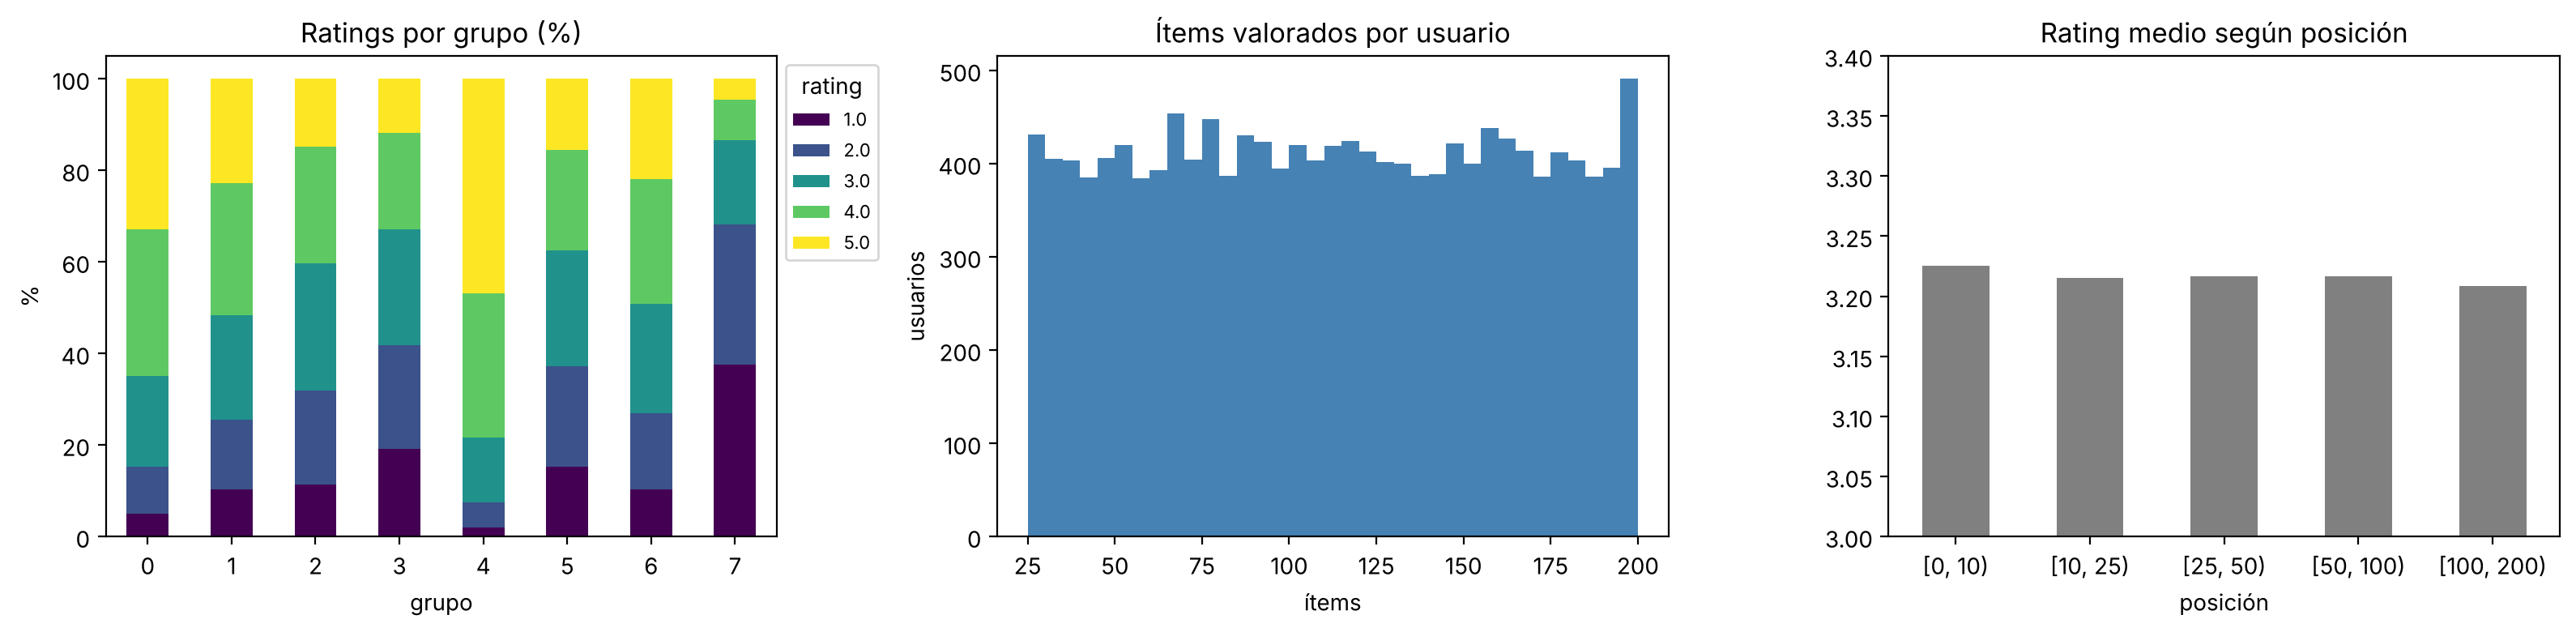

group,0,1,2,3,4,5,6,7
mean,3.775,3.387,3.119,2.837,4.156,3.008,3.34,2.123
std,1.156,1.271,1.221,1.282,0.994,1.293,1.27,1.145
count,199661.000,203160.000,201552.000,202536.000,201156.000,204881.000,199666.00,203347.000


In [3]:
df = pd.DataFrame([(u.user_id, u.group, pos, it, r) for u in train for pos, (it, r) in enumerate(zip(u.items, u.ratings))],
                  columns=["user_id", "group", "pos", "item", "rating"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
pct = pd.crosstab(df.group, df.rating, normalize="index") * 100
pct.plot.bar(stacked=True, ax=axes[0], colormap="viridis", rot=0, legend=False)
axes[0].set(title="Ratings por grupo (%)", xlabel="grupo", ylabel="%")
axes[0].legend(title="rating", bbox_to_anchor=(1, 1), fontsize=8)
largos = pd.Series([len(u.items) for u in train])
axes[1].hist(largos, bins=35, color="steelblue"); axes[1].set(title="Ítems valorados por usuario", xlabel="ítems", ylabel="usuarios")
pos_mean = df.groupby(pd.cut(df.pos, [0, 10, 25, 50, 100, 200], right=False), observed=True).rating.mean()
pos_mean.plot.bar(ax=axes[2], rot=0, color="gray"); axes[2].set(title="Rating medio según posición", ylim=(3, 3.4), xlabel="posición")
plt.tight_layout(); plt.show()
display(df.groupby("group").rating.agg(["mean", "std", "count"]).round(3).T)

In [4]:
# ¿Los ítems más mostrados son los mejor valorados? (indica cómo se generaron los logs)
by_item = df.groupby("item").rating.agg(["mean", "count"])
print("correlación (rating medio, apariciones) por ítem:", round(by_item.corr().iloc[0, 1], 3))
print("apariciones por ítem: mín", by_item["count"].min(), "máx", by_item["count"].max())

correlación (rating medio, apariciones) por ítem: -0.042
apariciones por ítem: mín 2011 máx 2288


**Conclusiones sobre los logs:**
- El rating medio es el mismo en cualquier posición de la trayectoria (≈ 3,22): el orden no aporta nada.
- La cantidad de veces que aparece un ítem no se relaciona con su rating medio (correlación ≈ 0). Los logs vienen de una **política uniforme al azar**: aparecer mucho no significa ser bueno. Por eso `popularity` no debería superar al azar.
- La distribución de ratings cambia por grupo: hay grupos más generosos y otros más exigentes.

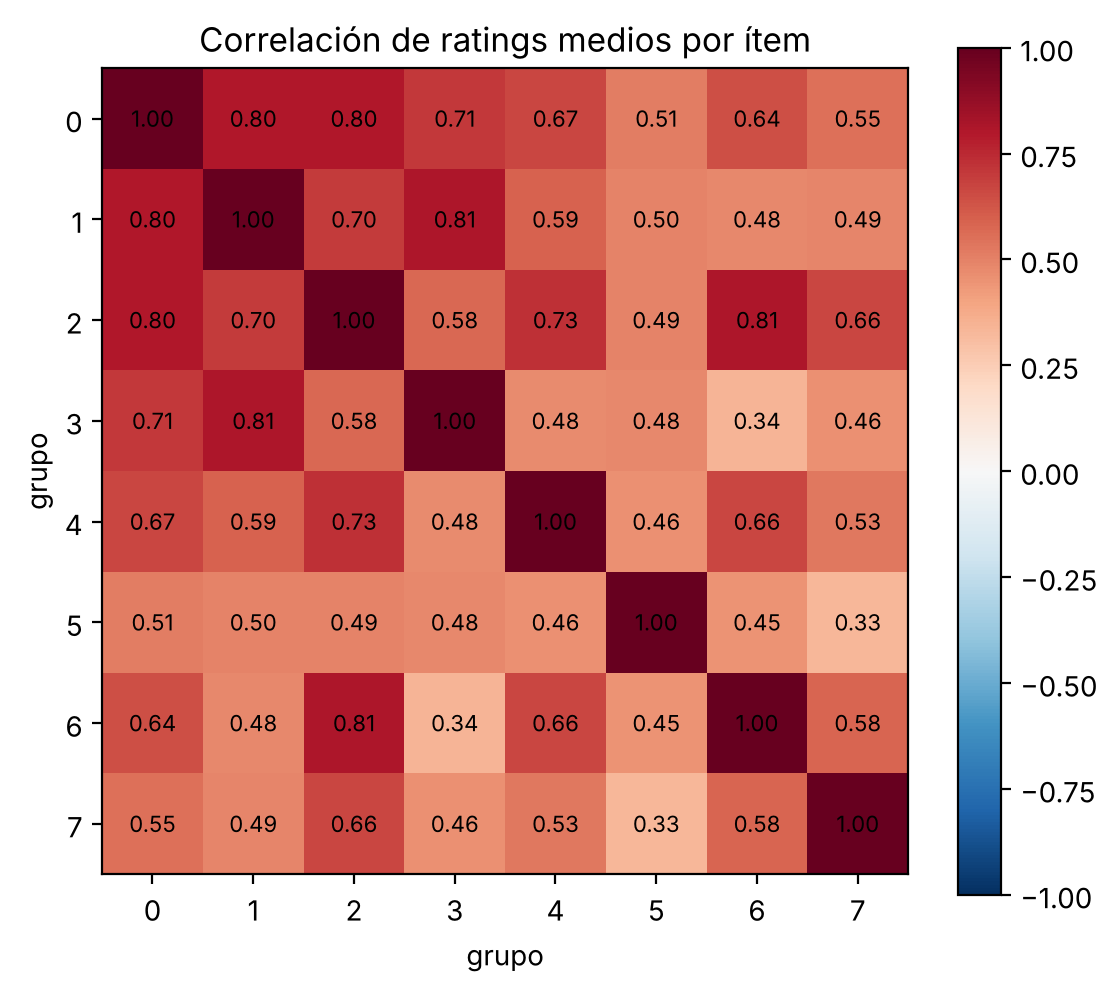

correlación media entre grupos distintos: 0.582
grupo más distinto (menor correlación media con los demás): 5


In [5]:
# Similitud entre grupos: correlación de los ratings medios por ítem
medias = df.pivot_table(index="item", columns="group", values="rating", aggfunc="mean")
corr = medias.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set(xticks=range(8), yticks=range(8), xlabel="grupo", ylabel="grupo", title="Correlación de ratings medios por ítem")
fig.colorbar(im); plt.show()
off = corr.where(~np.eye(8, dtype=bool))
print("correlación media entre grupos distintos:", round(off.stack().mean(), 3))
print("grupo más distinto (menor correlación media con los demás):", off.mean().idxmin())

In [6]:
# ¿Cuánto vale conocer el grupo? Rango de μ por ítem entre grupos (de groups/mu_netflix8.csv; sólo análisis)
mu = pd.read_csv(DATA_ROOT / "groups" / "mu_netflix8.csv", header=None).to_numpy()
mu = mu if mu.shape[0] == 8 else mu.T
rango = mu.max(0) - mu.min(0)
print("forma de μ:", mu.shape)
print(f"diferencia media entre el mejor y el peor grupo para un mismo ítem: {rango.mean():.2f} puntos")
print("top-20 global vs top-20 de cada grupo: ítems en común =",
      [len(set(np.argsort(-mu.mean(0))[:20]) & set(np.argsort(-mu[g])[:20])) for g in range(8)])

forma de μ: (8, 752)
diferencia media entre el mejor y el peor grupo para un mismo ítem: 2.51 puntos
top-20 global vs top-20 de cada grupo: ítems en común = [8, 9, 10, 11, 1, 8, 7, 13]


**Conclusiones sobre los grupos:** los grupos se parecen bastante (hay películas que gustan a todos) pero no son iguales. El top-20 global comparte sólo una parte del top-20 de cada grupo, así que **personalizar por grupo** debería mejorar sobre un ranking global. Ese es el margen que separa `item_mean` de `group_mean`. Cuando el grupo está oculto, la política tiene que inferirlo de los ratings que va viendo.

## 1.3 De la trayectoria al episodio y al retorno pendiente

Un **episodio** es un tramo de 20 interacciones consecutivas de un usuario (`make_episodes`). Un usuario con 112 ítems aporta 5 episodios y descarta los 12 sobrantes. Ningún episodio mezcla usuarios.

El **retorno pendiente** (return-to-go) en el paso t es la suma de los ratings que faltan en ese episodio:

$$\hat R_t = r_t + r_{t+1} + \dots + r_{19}, \qquad \hat R_{t+1} = \hat R_t - r_t$$

Se calcula **dentro del episodio**. Así su escala (20 a 100) coincide con la de una sesión evaluada de 20 pasos.

episodios de train: (73827, 20) | episodios de val: (8275, 20)


t,0,1,2,3,4,5
ítem a_t,472.0,97.0,122.0,654.0,709.0,467.0
rating r_t,4.0,3.0,4.0,3.0,5.0,4.0
R̂_t,76.0,72.0,69.0,65.0,62.0,57.0


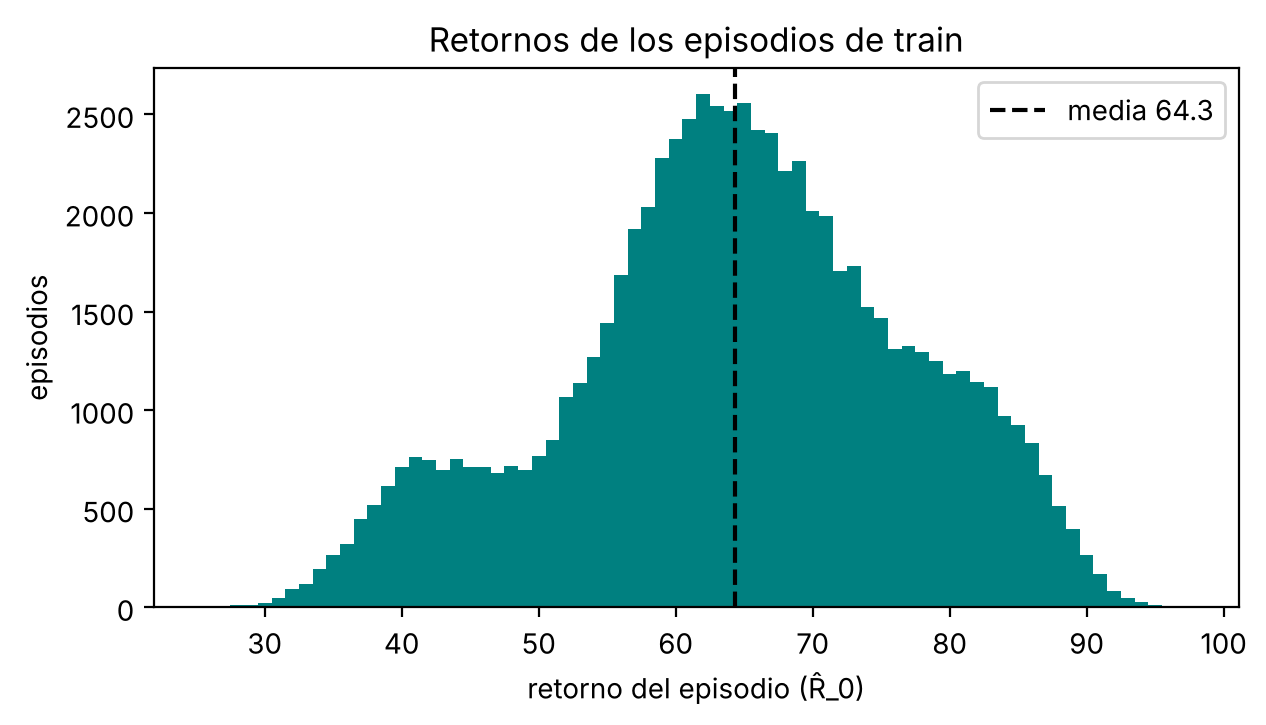

percentiles 10/50/90/99: [46. 65. 81. 89.] | mín 26.0 | máx 97.0


In [7]:
ep = make_episodes(train, 20)
rtg = ep.returns_to_go()
print("episodios de train:", ep.items.shape, "| episodios de val:", make_episodes(val, 20).items.shape)
u0 = pd.DataFrame({"t": range(20), "ítem a_t": ep.items[0], "rating r_t": ep.ratings[0], "R̂_t": rtg[0]}).set_index("t")
display(u0.head(6).T)
assert np.allclose(rtg[:, :-1] - ep.ratings[:, :-1], rtg[:, 1:])   # R̂_{t+1} = R̂_t − r_t
assert np.allclose(rtg[:, -1], ep.ratings[:, -1])                    # en el último paso R̂ = r

R = ep.ratings.sum(1)
plt.figure(figsize=(7, 3.5)); plt.hist(R, bins=np.arange(R.min(), R.max() + 2) - 0.5, color="teal")
plt.axvline(R.mean(), color="k", ls="--", label=f"media {R.mean():.1f}")
plt.xlabel("retorno del episodio (R̂_0)"); plt.ylabel("episodios"); plt.title("Retornos de los episodios de train"); plt.legend(); plt.show()
print("percentiles 10/50/90/99:", np.percentile(R, [10, 50, 90, 99]), "| mín", R.min(), "| máx", R.max())

Los retornos de train van de ~25 a ~97, con media 64. Ese es el **soporte** del retorno pedido al Decision Transformer: pedir más de ~97 es pedir algo que nunca vio.

In [8]:
# Retornos por grupo: los grupos generosos tienen episodios de retorno más alto
display(pd.DataFrame({"grupo": ep.groups, "retorno": R}).groupby("grupo").retorno.describe()[["mean", "std", "min", "max"]].round(1).T)

grupo,0,1,2,3,4,5,6,7
mean,75.5,67.7,62.4,56.7,83.1,60.2,66.8,42.5
std,5.1,5.7,5.5,5.7,4.4,5.8,5.6,5.1
min,56.0,42.0,44.0,35.0,65.0,38.0,44.0,26.0
max,94.0,89.0,82.0,82.0,97.0,86.0,85.0,66.0


## 1.4 El problema como MDP

| Elemento | Definición en este trabajo |
|---|---|
| Estado $s_t$ | lo que la política sabe al recomendar en el paso t: el grupo (si es visible; si no, "desconocido"), los ítems ya mostrados con sus ratings revelados y el número de paso t. **No** incluye $r_t$, que se revela después de mostrar $a_t$ |
| Acción $a_t$ | una película del catálogo que todavía no se mostró en la sesión |
| Recompensa $r_t$ | el rating (1–5) que el usuario le da a $a_t$ |
| Transición | se agrega $(a_t, r_t)$ al historial; el grupo no cambia |
| Horizonte | T = 20 pasos; el paso 19 es terminal |
| Descuento γ | el retorno evaluado es la suma sin descontar. En IQL se compara γ = 0 con γ = 0,9 (se elige en validación) |

**Qué información del estado usa cada modelo:**
- **Decision Transformer:** no resume el estado en un vector. Ve la secuencia completa de tokens $(\hat R_k, s_k, a_k)$ para k ≤ t. En cada token $s_k$ ponemos el grupo (o "desconocido") y el rating del paso anterior $r_{k-1}$. Así, con la atención sobre los pasos previos, tiene todo el historial (ítems y ratings) más el retorno que se le pide.
- **IQL:** necesita un vector de estado para calcular Q, V y π. Lo produce una GRU que recorre los pares $(a_k, r_k)$ previos, sumando el grupo (o "desconocido") y el paso t. Devuelve T + 1 estados $h_0 … h_{20}$, porque el objetivo de Q en t usa $V(s_{t+1})$.

**Grupo oculto:** en el 30 % de los episodios de entrenamiento se reemplaza el grupo por "desconocido" (en los dos modelos). Sin esto, el modelo nunca vería ese token y no sabría qué hacer en la condición de grupo oculto.

**¿Para qué sirve la secuencia si el rating no depende del orden?** Una recomendación no cambia los gustos del usuario, pero sí cambia **lo que la política sabe** de él: cada rating revelado da evidencia sobre su grupo. Con grupo visible casi no hay nada que aprender de la secuencia. Con grupo oculto, mostrar películas que distinguen grupos ayuda a recomendar mejor después. Ese es el único valor "secuencial" del problema, y es lo que mide la comparación γ = 0 frente a γ > 0 en IQL.

## 1.5 Evaluación: por qué sesiones simuladas

Los usuarios de test tienen rating para todo el catálogo, y el orden de sus IDs (0, 1, 2, …) no es un orden de consumo. Por eso **no** se evalúa "acertar el siguiente ID". Se usa el protocolo común: sesiones simuladas de 20 recomendaciones sin repetición, donde cada rating se revela recién al mostrar el ítem. La métrica principal es el retorno normalizado: 0 = azar, 1 = oráculo.